#Freight Rate Prediction: Exploratory Data Analysis

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Visual Theme Setup
plt.style.use('seaborn-v0_8-whitegrid')
TEAL = '#064A56'
CORAL = '#E07A5F'
SLATE = '#455A60'
COLORS = [TEAL, CORAL, '#3D405B', '#81B29A', '#F2CC8F']
sns.set_palette(COLORS)

BASE_DIR = Path('..') if Path('..').resolve().name == 'SpotterAi' or (Path('..') / 'train-test.csv').exists() else Path('.')
REPORT_DIR = BASE_DIR / 'reports'
REPORT_DIR.mkdir(exist_ok=True)
print(f'Working directory: {BASE_DIR.resolve()}')


Working directory: /Users/deepak/Deepak/SpotterAi


## 1. Data Ingestion & Shape Inspection

In [2]:
train = pd.read_csv(BASE_DIR / 'train-test.csv', parse_dates=['date'])
val = pd.read_csv(BASE_DIR / 'validation.csv', parse_dates=['date'])
dec = pd.read_csv(BASE_DIR / 'december-chart-inputs.csv', parse_dates=['date'])

print(f'Training set:   {train.shape[0]:>6,} rows × {train.shape[1]} columns')
print(f'Validation set: {val.shape[0]:>6,} rows × {val.shape[1]} columns')
print(f'December chart: {dec.shape[0]:>6,} rows × {dec.shape[1]} columns')
print(f'Training Date Range:   {train["date"].min().date()} → {train["date"].max().date()}')
print(f'Validation Date Range: {val["date"].min().date()} → {val["date"].max().date()}')
print(f'December Date Range:   {dec["date"].min().date()} → {dec["date"].max().date()}')


Training set:   48,000 rows × 14 columns
Validation set: 12,000 rows × 13 columns
December chart:     31 rows × 7 columns
Training Date Range:   2025-01-01 → 2025-10-31
Validation Date Range: 2025-11-01 → 2025-12-31
December Date Range:   2025-12-01 → 2025-12-31


## 2.Data Cleansing Requirements

In [3]:
print('--- Column Types ---')
print(train.dtypes.to_string())

print('\n--- Missing Values ---')
nulls = train.isnull().sum()
null_df = pd.DataFrame({'Missing Count': nulls, 'Pct (%)': (nulls / len(train) * 100).round(2)})
print(null_df[null_df['Missing Count'] > 0].to_string())
print(f'\nTotal rows with any missing value: {train.isnull().any(axis=1).sum():,}')

neg_w = (train['weight'] < 0).sum()
print(f'\nRows with negative weight: {neg_w}')
if neg_w > 0:
    print('  → Sign-flip data entry errors. Resolved using abs().')

cols_train = set(train.columns)
cols_val = set(val.columns)
cols_dec = set(dec.columns)
print(f'\nIn train but not validation: {cols_train - cols_val}')
print(f'In train but not december:   {cols_train - cols_dec}')
print('  → December benchmark lacks coordinates and market signals.')


--- Column Types ---
load_id                    str
pickup                     str
delivery                   str
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment                  str
weight                 float64
date            datetime64[us]
market_index           float64
quote_signal           float64
posted_rate            float64

--- Missing Values ---
              Missing Count  Pct (%)
weight                  300     0.62
market_index            374     0.78

Total rows with any missing value: 673

Rows with negative weight: 292
  → Sign-flip data entry errors. Resolved using abs().

In train but not validation: {'posted_rate'}
In train but not december:   {'posted_rate', 'quote_signal', 'pickup_lon', 'delivery_lat', 'market_index', 'delivery_lon', 'load_id', 'pickup_lat'}
  → December benchmark lacks coordinates and market signals.


## 3. Target Distribution & Rate-per-Mile

--- Descriptive Statistics ---
       posted_rate       rpm
count     48000.00  48000.00
mean       2373.98      2.22
std        1486.49      0.58
min          57.22      0.33
25%        1251.55      1.99
50%        2030.76      2.15
75%        3330.75      2.34
max       25533.00     14.13


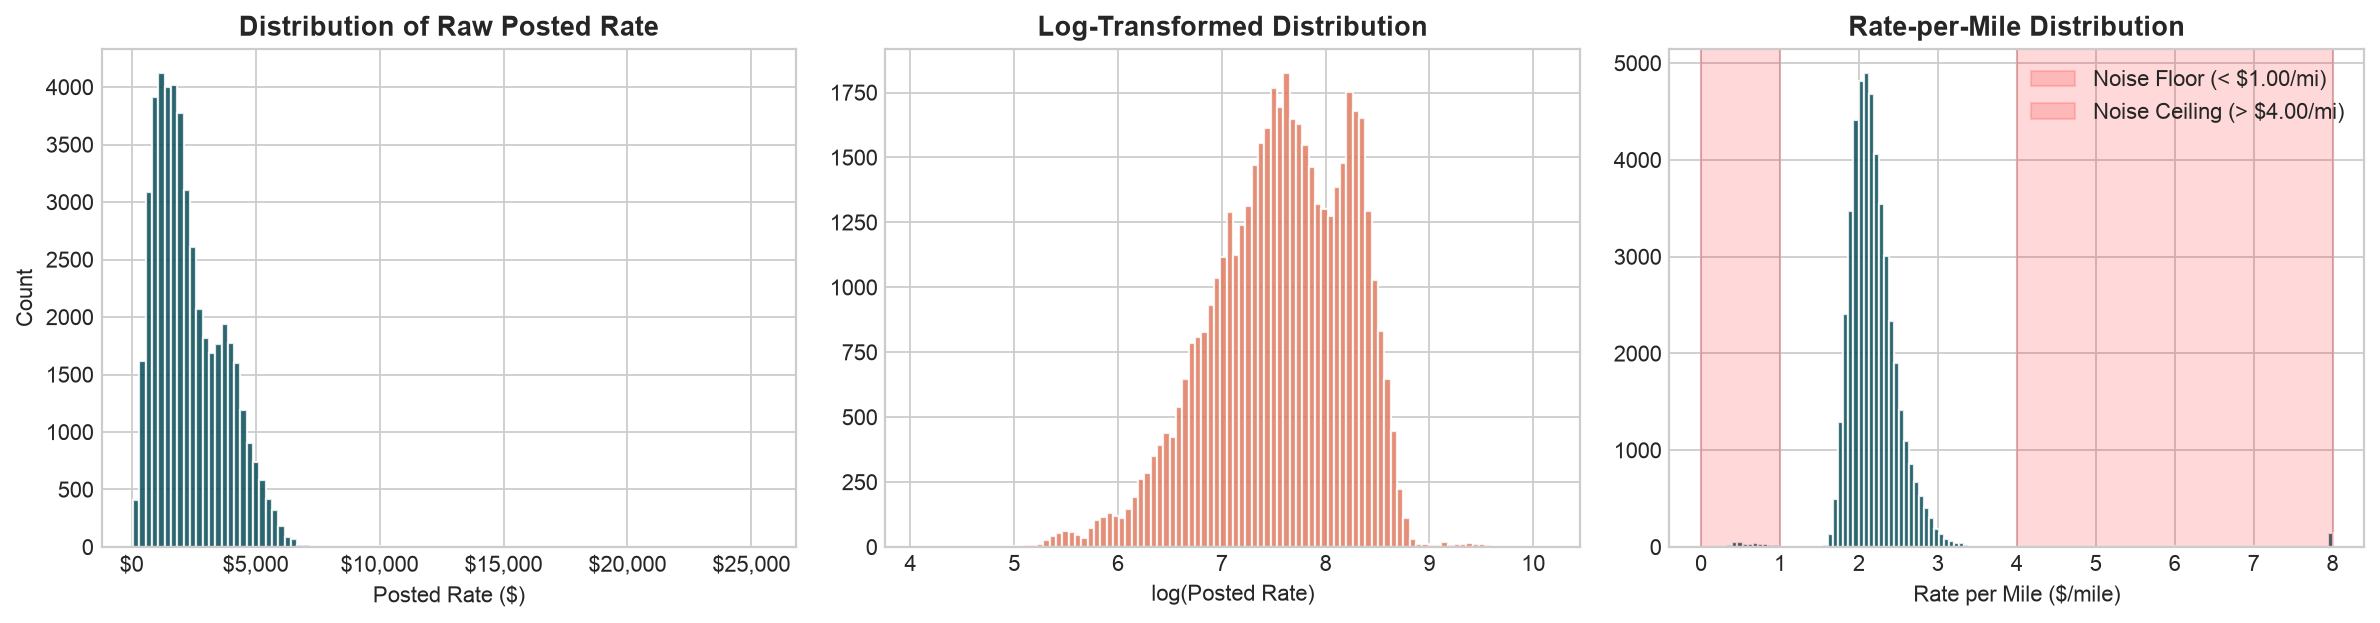

In [4]:
train['rpm'] = train['posted_rate'] / train['distance']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Raw posted rate
axes[0].hist(train['posted_rate'], bins=100, color=TEAL, alpha=0.85, edgecolor='white')
axes[0].set_xlabel('Posted Rate ($)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Raw Posted Rate', fontweight='bold')
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

# 2. Log-transformed rate
axes[1].hist(np.log1p(train['posted_rate']), bins=100, color=CORAL, alpha=0.85, edgecolor='white')
axes[1].set_xlabel('log(Posted Rate)')
axes[1].set_title('Log-Transformed Distribution', fontweight='bold')

# 3. Rate-per-Mile with noise boundaries
axes[2].hist(train['rpm'].clip(0, 8), bins=120, color=TEAL, alpha=0.85, edgecolor='white')
axes[2].axvspan(0, 1, color='red', alpha=0.15, label='Noise Floor (< $1.00/mi)')
axes[2].axvspan(4, 8, color='red', alpha=0.15, label='Noise Ceiling (> $4.00/mi)')
axes[2].set_xlabel('Rate per Mile ($/mile)')
axes[2].set_title('Rate-per-Mile Distribution', fontweight='bold')
axes[2].legend()

plt.tight_layout()
plt.savefig(REPORT_DIR / '01_target_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

print('--- Descriptive Statistics ---')
print(train[['posted_rate', 'rpm']].describe().round(2))


## 4. Distance Scaling 


--- Average Rate per Mile by Distance Band ---
            mean    std  count
dist_band                     
<250       2.759  0.242   2665
250-500    2.442  0.200   7471
500-1K     2.212  0.177  14835
1K-1.5K    2.092  0.153   8884
1.5K-2K    2.016  0.144   6020
2K-2.5K    1.949  0.140   4806
2.5K+      1.885  0.134   2650


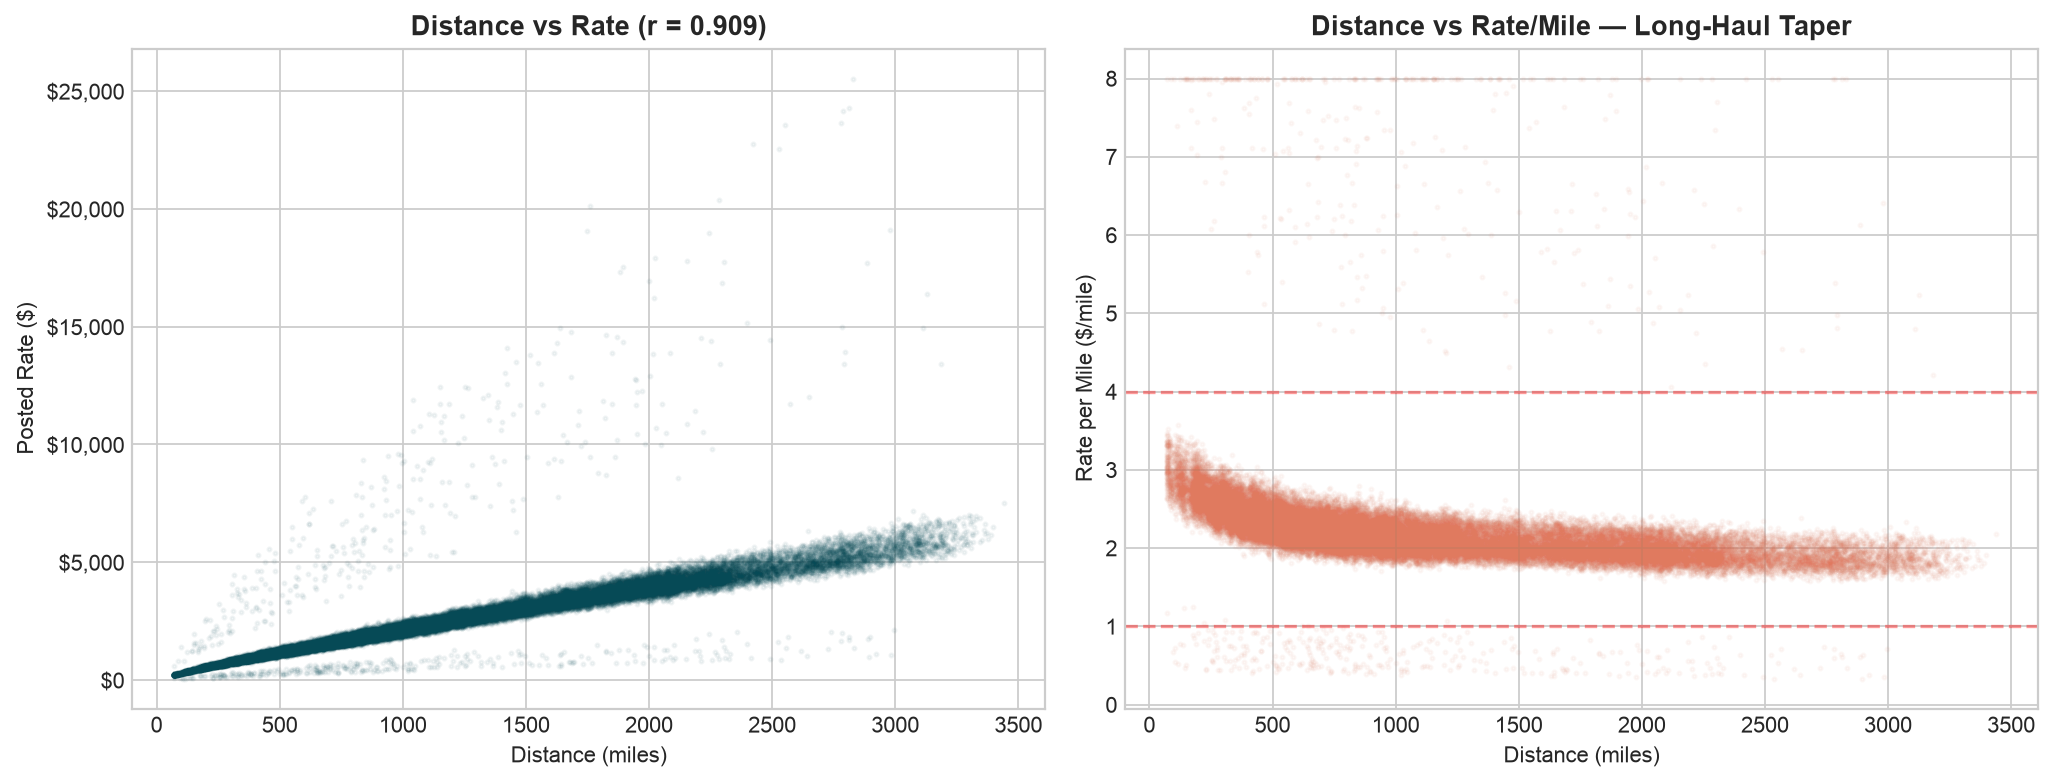

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distance vs Raw Dollar Rate
axes[0].scatter(train['distance'], train['posted_rate'], alpha=0.05, s=3, color=TEAL)
axes[0].set_xlabel('Distance (miles)')
axes[0].set_ylabel('Posted Rate ($)')
axes[0].set_title(f"Distance vs Rate (r = {train['distance'].corr(train['posted_rate']):.3f})", fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

# Distance vs Rate per Mile
axes[1].scatter(train['distance'], train['rpm'].clip(0, 8), alpha=0.05, s=3, color=CORAL)
axes[1].set_xlabel('Distance (miles)')
axes[1].set_ylabel('Rate per Mile ($/mile)')
axes[1].set_title('Distance vs Rate/Mile — Long-Haul Taper', fontweight='bold')
axes[1].axhline(y=1.0, color='red', linestyle='--', alpha=0.4)
axes[1].axhline(y=4.0, color='red', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(REPORT_DIR / '02_distance_analysis.png', dpi=160, bbox_inches='tight')
plt.show()

# Rate per Mile across distance bands
clean_subset = train[(train['rpm'] > 1.0) & (train['rpm'] < 4.0)].copy()
clean_subset['dist_band'] = pd.cut(clean_subset['distance'], bins=[0, 250, 500, 1000, 1500, 2000, 2500, 3500],
                                   labels=['<250', '250-500', '500-1K', '1K-1.5K', '1.5K-2K', '2K-2.5K', '2.5K+'])
print('--- Average Rate per Mile by Distance Band ---')
print(clean_subset.groupby('dist_band', observed=True)['rpm'].agg(['mean', 'std', 'count']).round(3))


## 5. Equipment Premiums & Monthly Seasonality

--- Equipment Statistics (Rate-per-Mile) ---
            mean    std  count
equipment                     
Dry Van    2.087  0.234  26836
Flatbed    2.263  0.258   8628
Reefer     2.356  0.265  11867


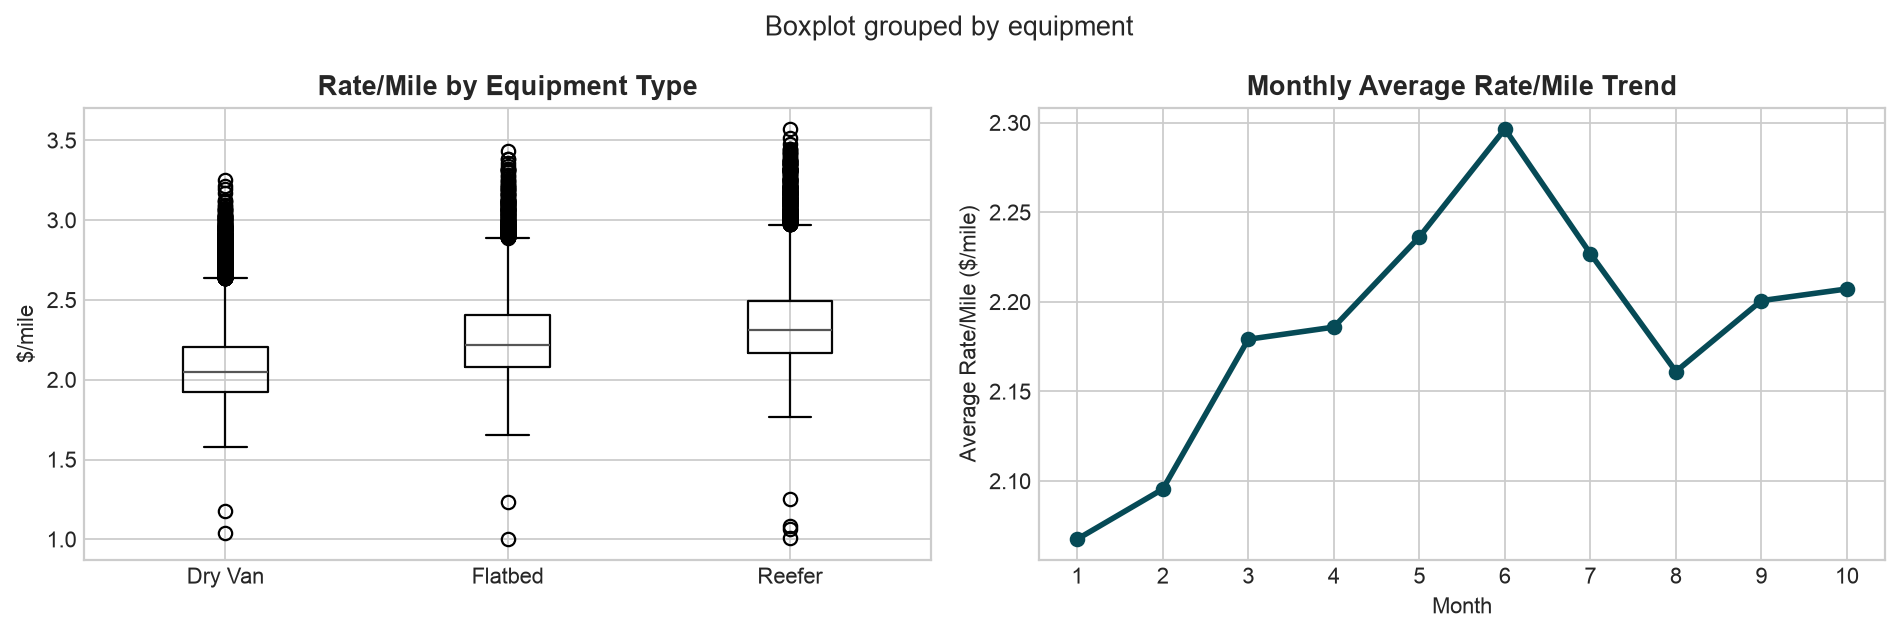

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

clean_subset.boxplot(column='rpm', by='equipment', ax=axes[0])
axes[0].set_title('Rate/Mile by Equipment Type', fontweight='bold')
axes[0].set_ylabel('$/mile')
axes[0].set_xlabel('')

monthly = clean_subset.groupby(clean_subset['date'].dt.month)['rpm'].mean()
axes[1].plot(monthly.index, monthly.values, color=TEAL, marker='o', linewidth=2.5)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Rate/Mile ($/mile)')
axes[1].set_title('Monthly Average Rate/Mile Trend', fontweight='bold')
axes[1].set_xticks(range(1, 11))

plt.tight_layout()
plt.savefig(REPORT_DIR / '03_feature_analysis.png', dpi=160, bbox_inches='tight')
plt.show()

print('--- Equipment Statistics (Rate-per-Mile) ---')
print(clean_subset.groupby('equipment')['rpm'].agg(['mean', 'std', 'count']).round(3))


## 6. Outlier Analysis

Total outlier loads: 669 (1.39%)
Outliers by equipment (%): {'Dry Van': 1.35, 'Flatbed': 1.43, 'Reefer': 1.48}
Outliers by month (%): {1: 1.65, 2: 1.27, 3: 1.41, 4: 1.37, 5: 1.24, 6: 1.28, 7: 1.32, 8: 1.39, 9: 1.37, 10: 1.63}


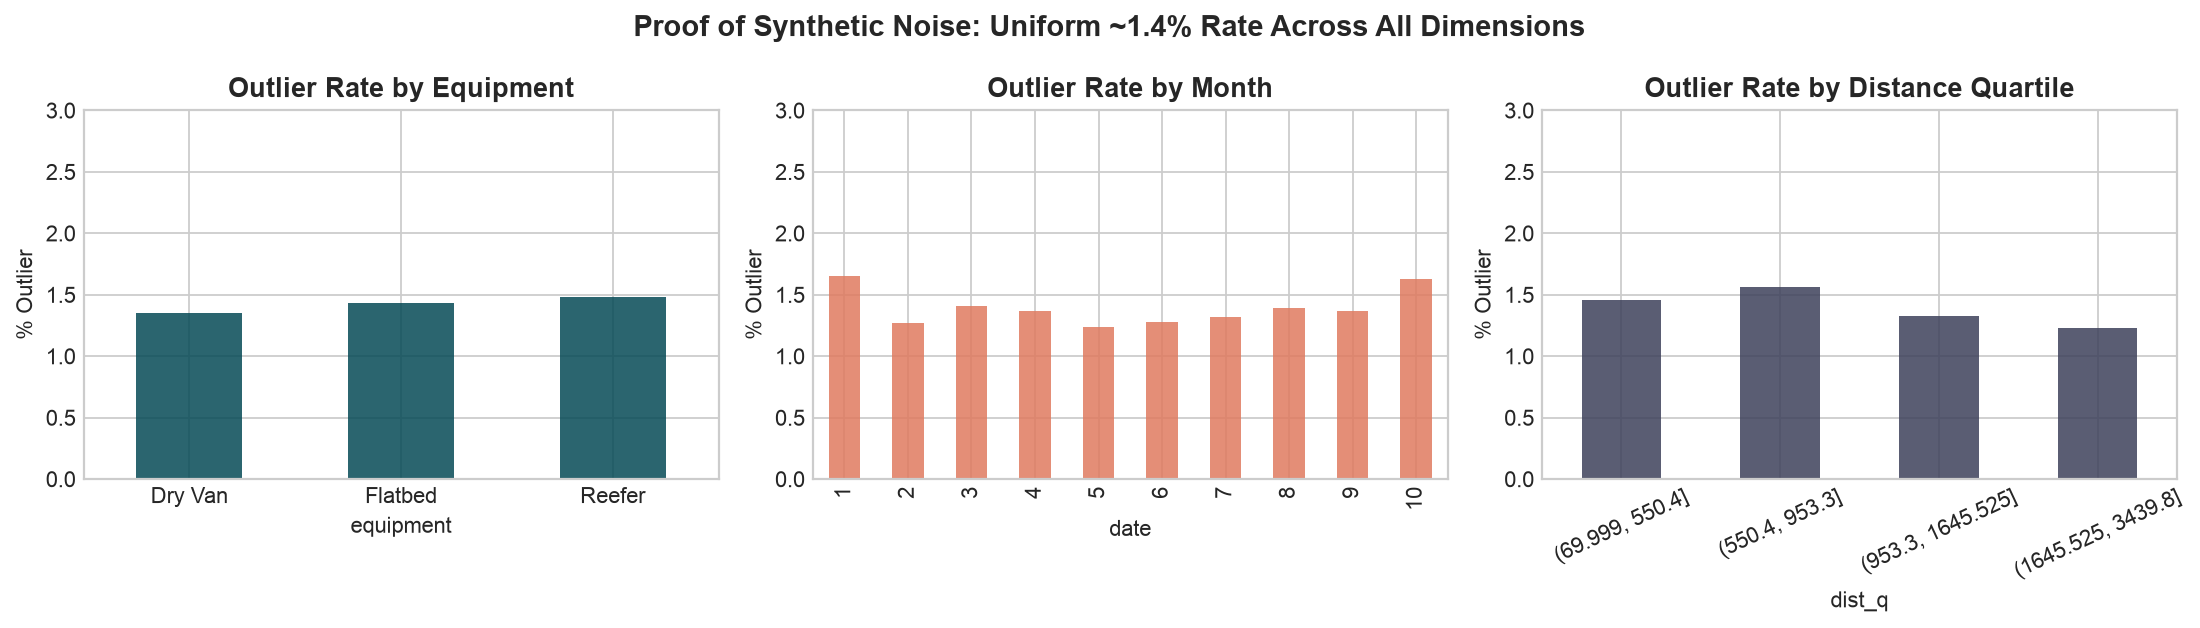

In [7]:
out_mask = (train['rpm'] <= 1.0) | (train['rpm'] >= 4.0)
t_out = train.assign(is_out=out_mask)

equip_out = (t_out.groupby('equipment')['is_out'].mean() * 100).round(2)
month_out = (t_out.groupby(t_out['date'].dt.month)['is_out'].mean() * 100).round(2)
t_out['dist_q'] = pd.qcut(t_out['distance'], 4)
dist_out = (t_out.groupby('dist_q', observed=True)['is_out'].mean() * 100).round(2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
equip_out.plot.bar(ax=axes[0], color=TEAL, alpha=0.85)
axes[0].set_title('Outlier Rate by Equipment', fontweight='bold')
axes[0].set_ylabel('% Outlier')
axes[0].set_ylim(0, 3)
axes[0].tick_params(axis='x', rotation=0)

month_out.plot.bar(ax=axes[1], color=CORAL, alpha=0.85)
axes[1].set_title('Outlier Rate by Month', fontweight='bold')
axes[1].set_ylabel('% Outlier')
axes[1].set_ylim(0, 3)

dist_out.plot.bar(ax=axes[2], color=COLORS[2], alpha=0.85)
axes[2].set_title('Outlier Rate by Distance Quartile', fontweight='bold')
axes[2].set_ylabel('% Outlier')
axes[2].set_ylim(0, 3)
axes[2].tick_params(axis='x', rotation=25)

plt.suptitle('Proof of Synthetic Noise: Uniform ~1.4% Rate Across All Dimensions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORT_DIR / '04_outlier_analysis.png', dpi=160, bbox_inches='tight')
plt.show()

print(f'Total outlier loads: {out_mask.sum():,} ({100*out_mask.sum()/len(train):.2f}%)')
print('Outliers by equipment (%):', equip_out.to_dict())
print('Outliers by month (%):', month_out.to_dict())


## 7. Market Signals & Macro Alignment



Daily macro tracking correlation: 0.6552


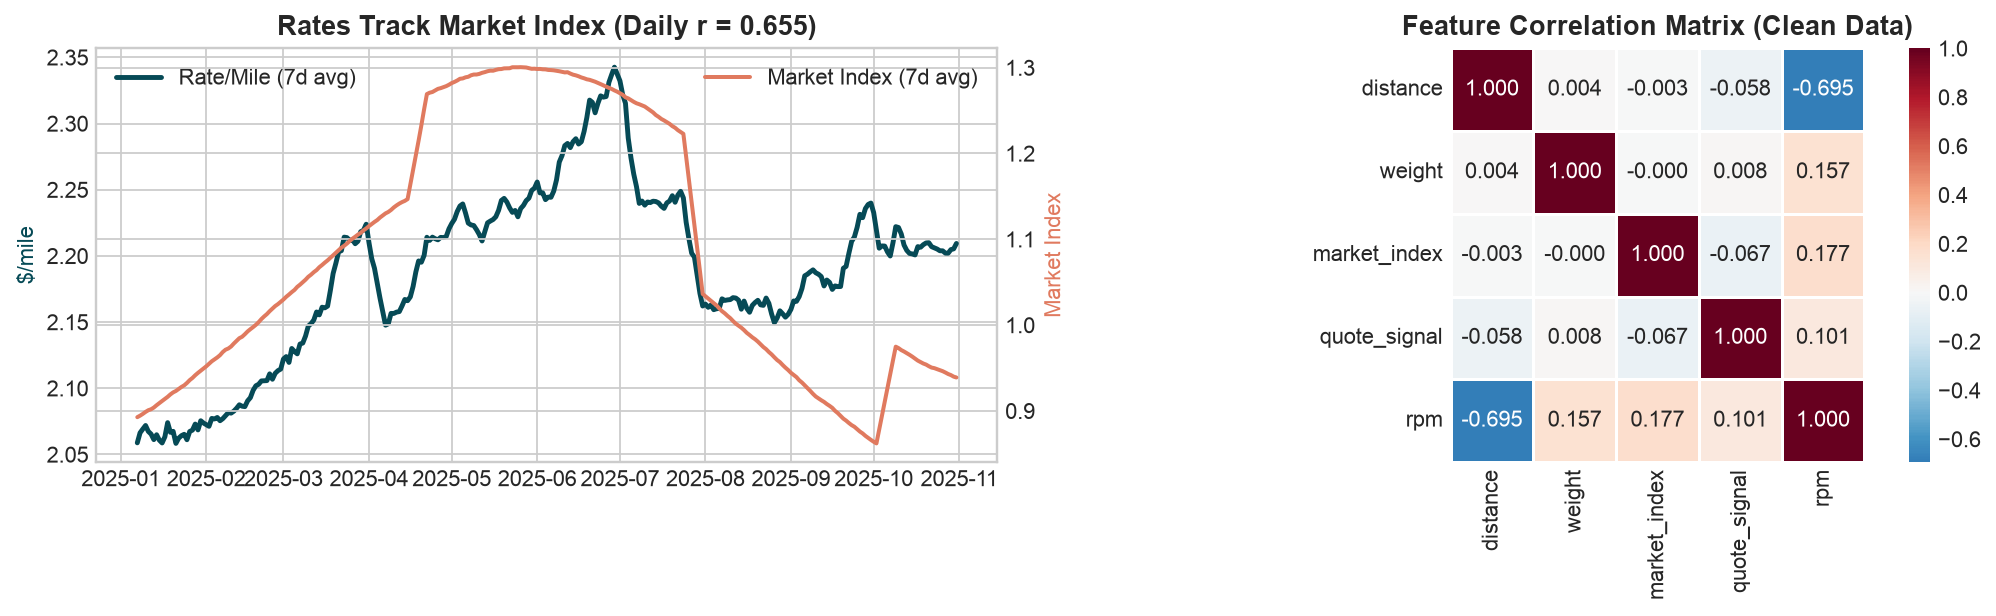

In [8]:
daily_eda = clean_subset.groupby('date').agg(rpm=('rpm', 'mean'), mi=('market_index', 'mean'))
daily_corr = daily_eda['rpm'].corr(daily_eda['mi'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 1. Macro time-series tracking
ax1 = axes[0]
ax2 = ax1.twinx()
ax1.plot(daily_eda.index, daily_eda['rpm'].rolling(7).mean(), color=TEAL, lw=2.2, label='Rate/Mile (7d avg)')
ax2.plot(daily_eda.index, daily_eda['mi'].rolling(7).mean(), color=CORAL, lw=1.8, label='Market Index (7d avg)')
ax1.set_ylabel('$/mile', color=TEAL)
ax2.set_ylabel('Market Index', color=CORAL)
ax1.set_title(f'Rates Track Market Index (Daily r = {daily_corr:.3f})', fontweight='bold')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# 2. Correlation heatmap
corr_cols = ['distance', 'weight', 'market_index', 'quote_signal', 'rpm']
corr_matrix = clean_subset[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=axes[1], square=True, linewidths=0.5)
axes[1].set_title('Feature Correlation Matrix (Clean Data)', fontweight='bold')

plt.tight_layout()
plt.savefig(REPORT_DIR / '05_market_signals.png', dpi=160, bbox_inches='tight')
plt.show()

print(f'Daily macro tracking correlation: {daily_corr:.4f}')


December lane historical loads: 32
Rate Range: $757.93 - $973.75
Mean Rate:  $856.59 ($2.36/mile)


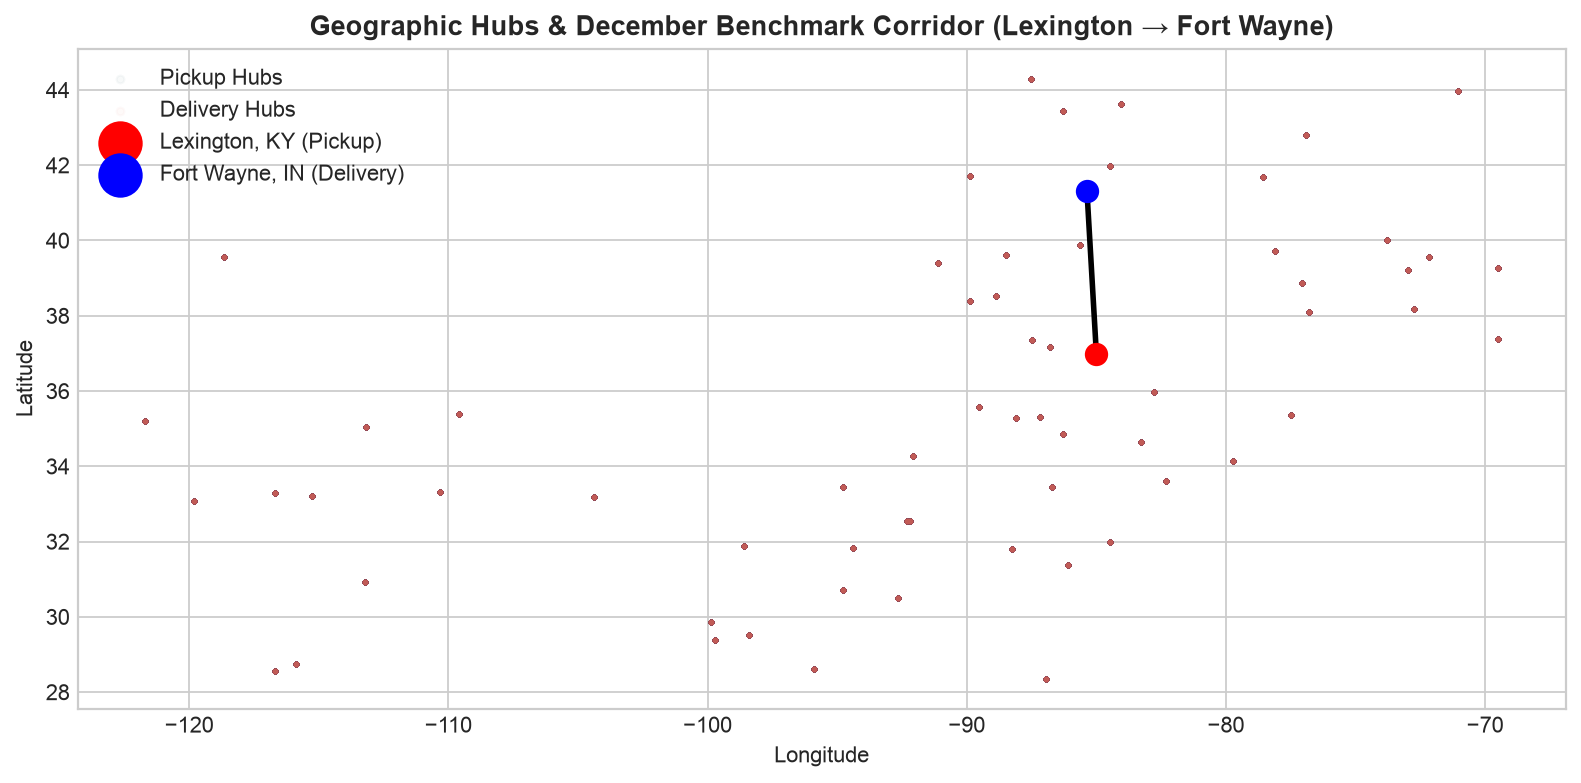

In [9]:
lex_fw = (train['pickup'] == 'Lexington') & (train['delivery'] == 'Fort Wayne')

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(train['pickup_lon'], train['pickup_lat'], alpha=0.03, s=3, color=TEAL, label='Pickup Hubs')
ax.scatter(train['delivery_lon'], train['delivery_lat'], alpha=0.03, s=3, color=CORAL, label='Delivery Hubs')
if lex_fw.sum() > 0:
    lex_row = train[lex_fw].iloc[0]
    ax.plot([lex_row['pickup_lon'], lex_row['delivery_lon']],
            [lex_row['pickup_lat'], lex_row['delivery_lat']],
            'k-', linewidth=2.5, zorder=5)
    ax.scatter([lex_row['pickup_lon']], [lex_row['pickup_lat']], c='red', s=90, zorder=6, label='Lexington, KY (Pickup)')
    ax.scatter([lex_row['delivery_lon']], [lex_row['delivery_lat']], c='blue', s=90, zorder=6, label='Fort Wayne, IN (Delivery)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Geographic Hubs & December Benchmark Corridor (Lexington → Fort Wayne)', fontweight='bold')
ax.legend(markerscale=2)

plt.tight_layout()
plt.savefig(REPORT_DIR / '06_geography.png', dpi=160, bbox_inches='tight')
plt.show()

lane_hist = train[lex_fw]
print(f'December lane historical loads: {len(lane_hist)}')
print(f'Rate Range: ${lane_hist["posted_rate"].min():.2f} - ${lane_hist["posted_rate"].max():.2f}')
print(f'Mean Rate:  ${lane_hist["posted_rate"].mean():.2f} (${lane_hist["rpm"].mean():.2f}/mile)')


In [10]:
val_dates = set(val['date'].dt.date)
dec_dates = set(dec['date'].dt.date)
overlap = dec_dates.intersection(val_dates)
print(f'December dates covered in validation dataset: {len(overlap)}/31 days')
print('  → Full concurrent market signals are available for December forecasting.')


December dates covered in validation dataset: 31/31 days
  → Full concurrent market signals are available for December forecasting.
